In [3]:
#Data Download
import requests
import pandas as pd

BASE_URL = "https://api.worldbank.org/v2"
COUNTRIES = {"PAK": "Pakistan", "IND": "India", "BGD": "Bangladesh"}
START_YEAR, END_YEAR = 2010, 2024
INDICATORS = {
    "NY.GDP.PCAP.KD.ZG": "GDP per capita growth (annual %)",
    "IT.NET.USER.ZS": "Individuals using the Internet (% of population)",
    "IT.NET.BBND.P2": "Fixed broadband subscriptions (per 100 people)",
}

def fetch_indicator(code):
    url = f"{BASE_URL}/country/{';'.join(COUNTRIES)}/indicator/{code}"
    params = {"format": "json", "date": f"{START_YEAR}:{END_YEAR}",
              "per_page": 1000, "page": 1}
    rows = []
    while True:
        r = requests.get(url, params=params, timeout=30)
        r.raise_for_status()
        payload = r.json()
        if len(payload) < 2 or payload[1] is None:
            raise ValueError(f"No data for {code}: {payload[0]}")
        meta, records = payload
        for rec in records:
            rows.append({"country_code": rec["countryiso3code"],
                         "year": int(rec["date"]),
                         "indicator": code,
                         "value": rec["value"]})
        if params["page"] >= meta["pages"]:
            break
        params["page"] += 1
    return pd.DataFrame(rows)

frames = []
for code in INDICATORS:
    try:
        frames.append(fetch_indicator(code))
        print("Downloaded:", code)
    except Exception as e:
        print("FAILED:", code, "->", e)

raw = pd.concat(frames, ignore_index=True)

# Full grid, so a missing row can never hide
full_index = pd.MultiIndex.from_product(
    [COUNTRIES.keys(), range(START_YEAR, END_YEAR + 1), INDICATORS.keys()],
    names=["country_code", "year", "indicator"])
df = (raw.set_index(["country_code", "year", "indicator"])
         .reindex(full_index).reset_index())
df["value"] = pd.to_numeric(df["value"], errors="coerce")
df["country"] = df["country_code"].map(COUNTRIES)

df.to_csv("wdi_raw_long_2010_2024.csv", index=False)
print(df.shape)   # expect (135, 5)

Downloaded: NY.GDP.PCAP.KD.ZG
Downloaded: IT.NET.USER.ZS
Downloaded: IT.NET.BBND.P2
(135, 5)


In [8]:
#check availability
expected = len(COUNTRIES) * (END_YEAR - START_YEAR + 1)   # 45

summary = (df.groupby("indicator")["value"]
             .agg(available="count", missing=lambda s: s.isna().sum())
             .assign(expected=expected))
print(summary)

print("\nMissing country-years:")
print(df[df["value"].isna()][["indicator", "country", "year"]].to_string(index=False))

                   available  missing  expected
indicator                                      
IT.NET.BBND.P2            45        0        45
IT.NET.USER.ZS            42        3        45
NY.GDP.PCAP.KD.ZG         45        0        45

Missing country-years:
     indicator  country  year
IT.NET.USER.ZS Pakistan  2021
IT.NET.USER.ZS Pakistan  2022
IT.NET.USER.ZS Pakistan  2023


In [9]:
# Duplicates: is any country-year repeated?
print("Duplicate country-years:", eda_data.duplicated(["country_code", "year"]).sum())

# Impossible values
print("Internet users outside 0-100:", (~eda_data["internet_users"].dropna().between(0, 100)).sum())
print("Broadband below 0:", (eda_data["broadband"] < 0).sum())

# Same value as the previous year, per country
for col in ["gdp_growth", "internet_users", "broadband"]:
    same = eda_data.groupby("country")[col].diff() == 0
    print(f"\n{col}: repeated values")
    print(eda_data.loc[same, ["country", "year", col]].to_string(index=False) if same.any() else "none")

# Unique countries
print("\nCountries:", eda_data["country"].nunique(), "| Codes:", eda_data["country_code"].nunique())

NameError: name 'eda_data' is not defined

In [5]:
short_names = {"NY.GDP.PCAP.KD.ZG": "gdp_growth",
               "IT.NET.USER.ZS": "internet_users",
               "IT.NET.BBND.P2": "broadband"}
variables = list(short_names.values())

data = (df.pivot(index=["country_code", "country", "year"],
                 columns="indicator", values="value")
          .rename(columns=short_names).reset_index())
data.columns.name = None
data.shape


(45, 6)

In [10]:
eda_data = data.copy()
model_data = data.dropna(subset=variables).copy()
print(eda_data.shape, model_data.shape)

(45, 6) (42, 6)


In [11]:
eda_data.to_csv("wdi_prepared_eda.csv", index=False)
model_data.to_csv("wdi_prepared_model.csv", index=False)
import os
print(os.listdir())

['.config', 'wdi_prepared_eda.csv', 'wdi_prepared_model.csv', 'wdi_raw_long_2010_2024.csv', 'sample_data']


In [12]:
from google.colab import files
files.download("wdi_prepared_eda.csv")
files.download("wdi_prepared_model.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
#EDA
#step 1 # Structure
#How many rows and columns?
eda_data.shape

(45, 6)

In [14]:
#What are the column names and data types?
eda_data.columns
eda_data.dtypes
eda_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country_code    45 non-null     object 
 1   country         45 non-null     object 
 2   year            45 non-null     int64  
 3   broadband       45 non-null     float64
 4   internet_users  42 non-null     float64
 5   gdp_growth      45 non-null     float64
dtypes: float64(3), int64(1), object(2)
memory usage: 2.2+ KB


In [15]:
# What do the first and last rows look like?
eda_data.head()
eda_data.tail()

,country_code,country,year,broadband,internet_users,gdp_growth
40,PAK,Pakistan,2020,1.039540,18.935,-3.038893
41,PAK,Pakistan,2021,1.231441,NaN,4.523046
42,PAK,Pakistan,2022,1.283719,NaN,2.962503
43,PAK,Pakistan,2023,1.356224,NaN,-1.945431
44,PAK,Pakistan,2024,1.465594,57.253,1.537329


In [16]:
# How many missing values in each column?
eda_data.isnull().sum()

,0
country_code,0
country,0
year,0
broadband,0
internet_users,3
gdp_growth,0


In [17]:
# Does each country have exactly 15 rows?
eda_data.groupby("country").size()

,0
country,
Bangladesh,15
India,15
Pakistan,15


In [18]:
# Step 2: Summary statistics
# For each of the 3 variables: what are the count, mean, median, std, min and max?
eda_data[["gdp_growth", "internet_users", "broadband"]].describe()

,gdp_growth,internet_users,broadband
count,45.000000,42.000000,45.000000
mean,3.979770,23.011071,2.218330
std,2.980379,17.674422,2.122016
min,-6.690471,3.700000,0.272381
25%,2.766486,10.017500,0.952871
50%,4.977700,15.920000,1.283719
75%,6.063981,34.677600,2.745347
max,8.790934,64.943497,8.089311


In [19]:
eda_data.groupby("country")[variables].median().round(2)

,gdp_growth,internet_users,broadband
country,,,
Bangladesh,5.51,21.50,4.50
India,6.06,18.20,1.32
Pakistan,2.57,11.69,0.95


In [20]:
eda_data.loc[eda_data["gdp_growth"].idxmin(), ["country", "year", "gdp_growth"]]

,25
country,India
year,2020
gdp_growth,-6.690471


In [21]:
eda_data.sort_values("gdp_growth").head(3)

,country_code,country,year,broadband,internet_users,gdp_growth
25,IND,India,2020,1.636226,43.405443,-6.690471
40,PAK,Pakistan,2020,1.039540,18.935000,-3.038893
43,PAK,Pakistan,2023,1.356224,NaN,-1.945431


In [22]:
internet = eda_data.pivot(index="year", columns="country", values="internet_users")
internet.loc[[2010, 2024]]

country,Bangladesh,India,Pakistan
year,,,
2010,3.700000,7.500000,8.000
2024,53.421713,64.943497,57.253


In [23]:
broadband = eda_data.pivot(index="year", columns="country", values="broadband")
broadband.loc[[2010, 2024]]

country,Bangladesh,India,Pakistan
year,,,
2010,0.272381,0.883809,0.396251
2024,8.089311,3.150463,1.465594


In [24]:
import matplotlib.pyplot as plt

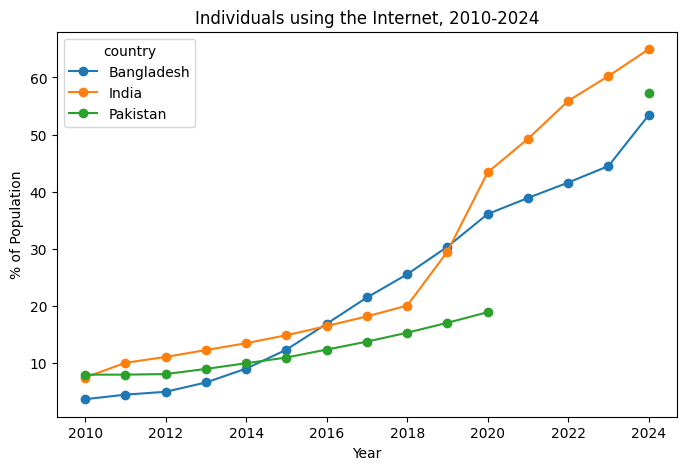

In [25]:
# line charts
# Which country will be on top at the end of the internet chart?

internet.plot(figsize=(8, 5), marker="o")
plt.title("Individuals using the Internet, 2010-2024")
plt.xlabel("Year")
plt.ylabel("% of Population")
plt.show()

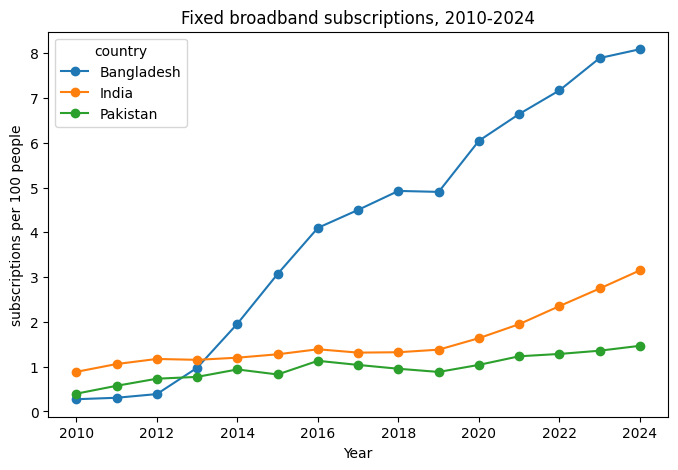

In [26]:
# which country pulls away, and from which year?
broadband.plot(figsize=(8, 5), marker="o")
plt.title("Fixed broadband subscriptions, 2010-2024")
plt.xlabel("Year")
plt.ylabel("subscriptions per 100 people")
plt.show()

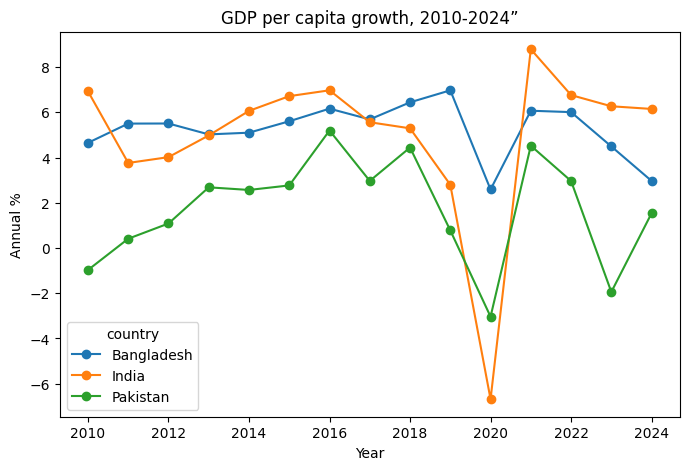

In [27]:
# is there a shared dip? Which country moves up and down the most?
# pivot_table
gdp = eda_data.pivot(index="year", columns=("country"),values=("gdp_growth"))
# chart
gdp.plot(figsize=(8, 5), marker="o")
plt.title("GDP per capita growth, 2010-2024”")
plt.xlabel("Year")
plt.ylabel("Annual %")
plt.show()

In [30]:
# Correlations
# What is the correlation between the 3 variables, all countries together?

variables = ["gdp_growth", "internet_users", "broadband"]
model_data[variables].corr().round(2)

,gdp_growth,internet_users,broadband
gdp_growth,1.00,0.07,0.23
internet_users,0.07,1.00,0.58
broadband,0.23,0.58,1.00


In [29]:
import seaborn as sns

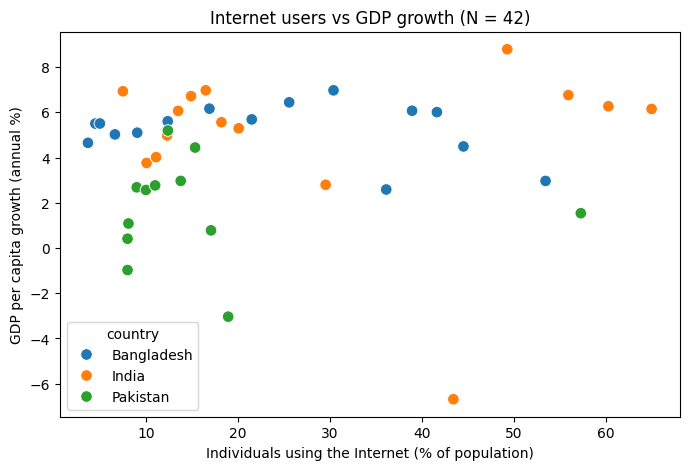

In [31]:
#Scatter plot: internet users vs GDP growth
plt.figure(figsize=(8, 5))
sns.scatterplot(data=model_data, x= "internet_users", y="gdp_growth", hue="country",s=70)
plt.title("Internet users vs GDP growth (N = 42)")
plt.xlabel("Individuals using the Internet (% of population)")
plt.ylabel("GDP per capita growth (annual %)")
plt.show()


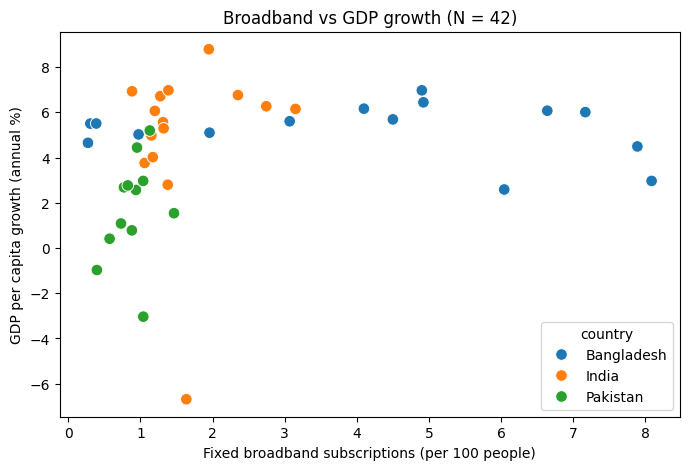

In [32]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=model_data, x= "broadband", y="gdp_growth", hue="country",s=70)
plt.title("Broadband vs GDP growth (N = 42)")
plt.xlabel("Fixed broadband subscriptions (per 100 people)")
plt.ylabel("GDP per capita growth (annual %)")
plt.show()


In [33]:
# Correlation by country
for country, g in model_data.groupby("country"):
  print(country, "(N=", len(g),")")
  print(g[variables].corr().round(2))
  print()


Bangladesh (N= 15 )
                gdp_growth  internet_users  broadband
gdp_growth            1.00           -0.28      -0.19
internet_users       -0.28            1.00       0.98
broadband            -0.19            0.98       1.00

India (N= 15 )
                gdp_growth  internet_users  broadband
gdp_growth            1.00           -0.04       0.12
internet_users       -0.04            1.00       0.95
broadband             0.12            0.95       1.00

Pakistan (N= 12 )
                gdp_growth  internet_users  broadband
gdp_growth            1.00           -0.06       0.31
internet_users       -0.06            1.00       0.77
broadband             0.31            0.77       1.00



In [34]:
model_data[model_data["year"] != 2020][variables].corr().round(2)

,gdp_growth,internet_users,broadband
gdp_growth,1.00,0.26,0.28
internet_users,0.26,1.00,0.59
broadband,0.28,0.59,1.00


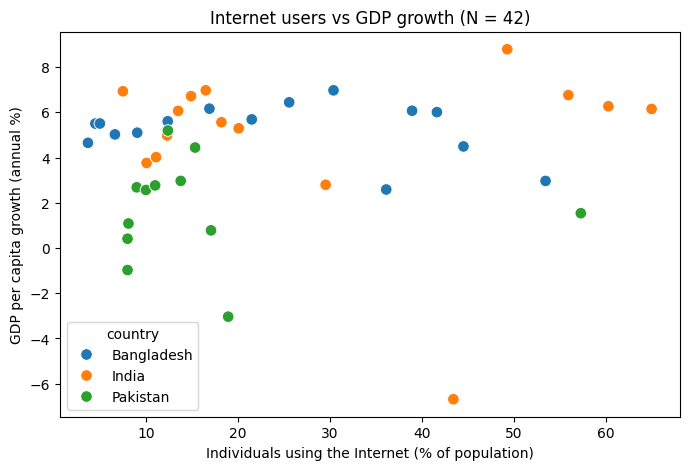

In [35]:
# Scatter plot chart
plt.figure(figsize=(8, 5))
sns.scatterplot(data=model_data, x="internet_users", y="gdp_growth", hue="country", s=70)
plt.title("Internet users vs GDP growth (N = 42)")
plt.xlabel("Individuals using the Internet (% of population)")
plt.ylabel("GDP per capita growth (annual %)")
plt.show()

In [ ]:
# Main findings
# India: Highest median GDP growth and largest increase in internet usage.
# Bangladesh: Strongest broadband expansion, reaching 8.09 subscriptions per 100 people.
# Pakistan: Lowest median GDP growth and broadband access.
# Relationships: GDP growth has weak correlations with both digital connectivity indicators.
# Digital access: Internet usage and broadband move strongly together in all three countries.

# Limitations (for my README)
# Only 3 countries and 15 years, so the results are descriptive and not proof.
# Pakistan’s internet use is missing for 2021 to 2023. These values were left blank, not estimated, so correlations that use internet data have 42 rows.
# Internet use and broadband rise over time, so their strong correlation partly reflects a shared trend.
# Correlation does not show cause and effect.
# One unusual year (2020) can change a result.


In [36]:
from google.colab import files
files.download("wdi_prepared_eda.csv")
files.download("wdi_prepared_model.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
# GDP stability
# which country’s GDP growth moves around the most?

eda_data.groupby("country")["gdp_growth"].agg(["mean", "std", "min", "max"]).round(2)

,mean,std,min,max
country,,,,
Bangladesh,5.25,1.20,2.59,6.97
India,4.96,3.55,-6.69,8.79
Pakistan,1.73,2.38,-3.04,5.20


In [38]:
eda_data[eda_data["year"] != 2020].groupby("country")["gdp_growth"].std().round(2)

,gdp_growth
country,
Bangladesh,0.99
India,1.55
Pakistan,2.06


In [39]:
# Pandemic comparison
# how did each country’s GDP growth change around 2020?
gdp = eda_data.pivot(index="year", columns="country", values="gdp_growth")
gdp.loc[[2019, 2020, 2021]].round(2)

country,Bangladesh,India,Pakistan
year,,,
2019,6.97,2.80,0.78
2020,2.59,-6.69,-3.04
2021,6.07,8.79,4.52


In [40]:
# change
(gdp.loc[2020] - gdp.loc[2019]).round(2)
(gdp.loc[2021] - gdp.loc[2020]).round(2)

,0
country,
Bangladesh,3.48
India,15.48
Pakistan,7.56


In [41]:
# Digital divide
# how big is the gap in internet use between the highest and lowest country, and did it grow?
net = eda_data.pivot(index="year", columns="country", values="internet_users")
net_all = net.dropna()

In [42]:
# Calculate the gap.
gap = net_all.max(axis=1) - net_all.min(axis=1)
gap.round(2)

,0
year,
2010,4.30
2011,5.57
2012,6.10
2013,5.67
2014,4.45
2015,3.90
2016,4.51
2017,7.72
2018,10.23


In [43]:
# Calculate the ratio.
(net_all.max(axis=1) / net_all.min(axis=1)).round(2)

,0
year,
2010,2.16
2011,2.24
2012,2.22
2013,1.86
2014,1.49
2015,1.35
2016,1.36
2017,1.56
2018,1.67


In [44]:
# Pandemic comparison
# how did each country’s GDP growth change around 2020?
gdp = eda_data.pivot(index="year", columns="country", values="gdp_growth")
gdp.loc[[2019, 2020, 2021]].round(2)

country,Bangladesh,India,Pakistan
year,,,
2019,6.97,2.80,0.78
2020,2.59,-6.69,-3.04
2021,6.07,8.79,4.52


In [46]:
# Calculate the fall and the rebound
fall = (gdp.loc[2020]- gdp.loc[2019]).round(2)
rebound = (gdp.loc[2021]- gdp.loc[2020]).round(2)
print("Change 2019 to 2020:\n",fall)
print("Change 2020 to 2021:\n",rebound)

Change 2019 to 2020:
 country
Bangladesh   -4.39
India        -9.49
Pakistan     -3.82
dtype: float64
Change 2020 to 2021:
 country
Bangladesh     3.48
India         15.48
Pakistan       7.56
dtype: float64


In [49]:
# Digital Divide
net = eda_data.pivot(index="year",columns="country", values="internet_users")
net_all = net.dropna()
gap = net_all.max(axis=1) - net_all.min(axis=1)

gap.round(2)

,0
year,
2010,4.30
2011,5.57
2012,6.10
2013,5.67
2014,4.45
2015,3.90
2016,4.51
2017,7.72
2018,10.23


In [50]:
(net_all.max(axis=1) / net_all.min(axis=1)).round(2)

,0
year,
2010,2.16
2011,2.24
2012,2.22
2013,1.86
2014,1.49
2015,1.35
2016,1.36
2017,1.56
2018,1.67
